In [1]:
import pandas as pd
purchases = pd.read_csv("新新出入境数据（英文版）.csv")
print("rows, columns:", purchases.shape)
print(purchases.head())

rows, columns: (23428, 7)
         Date                   Control Point Arrival / Departure  \
0  13-11-2023                         Airport             Arrival   
1  13-11-2023                         Airport           Departure   
2  13-11-2023  Express Rail Link West Kowloon             Arrival   
3  13-11-2023  Express Rail Link West Kowloon           Departure   
4  13-11-2023                           Lo Wu             Arrival   

   Hong Kong Residents  Mainland Visitors  Other Visitors  Total  
0                29286               7737           18942  55965  
1                24590               5925           17591  48106  
2                14226              12544             984  27754  
3                11981              10275            1063  23319  
4                61184              11195             700  73079  


In [7]:
import pandas as pd

# 增加这两行显示设置，防止控制台输出折行错位
pd.set_option('display.max_columns', None)  # 显示所有列
pd.set_option('display.width', 1000)        # 设置显示总宽度，数字可调大

df = pd.read_csv("新新出入境数据（英文版）.csv")
numeric_cols = ['Hong Kong Residents', 'Mainland Visitors', 'Other Visitors', 'Total']

grouped_stats = df.groupby('Control Point')[numeric_cols].agg(
    ['max', 'min', 'mean', 'median', 'var']
)

print(grouped_stats.round(2))

                               Hong Kong Residents                                        Mainland Visitors                                      Other Visitors                                       Total                                       
                                               max   min      mean   median           var               max  min      mean   median          var            max min      mean   median          var     max   min      mean   median           var
Control Point                                                                                                                                                                                                                                     
Airport                                      77540    24  31596.54  29729.5  7.465752e+07             48740    2  10394.98   9429.5  17308185.00          36173  14  18331.32  17841.5  17405002.28   93386    88  60322.83  59536.0  8.984565e+07
China Ferry Terminal        

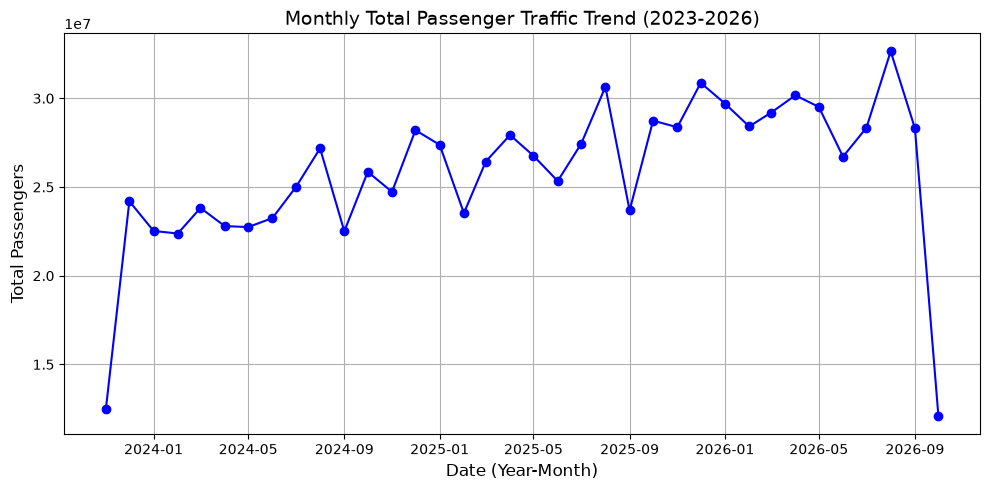

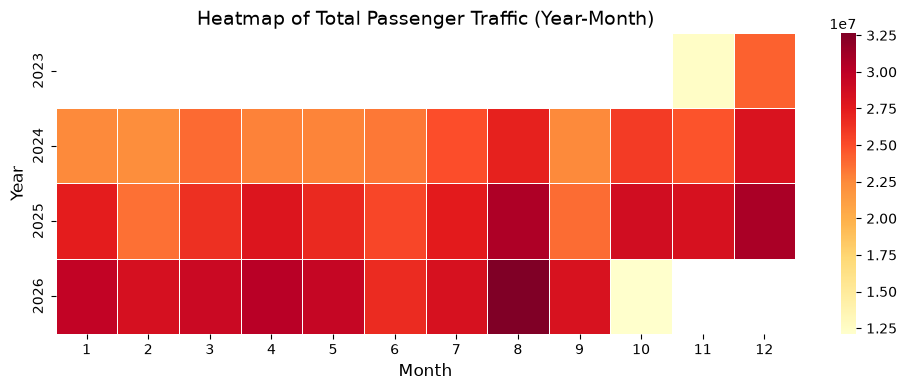

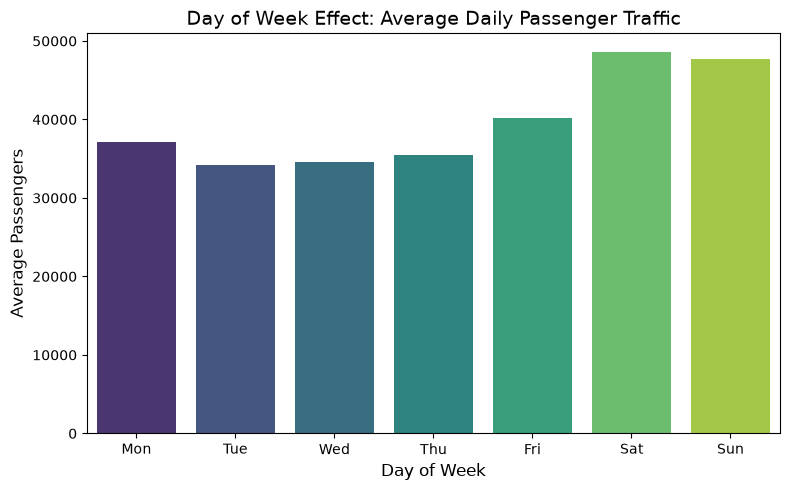

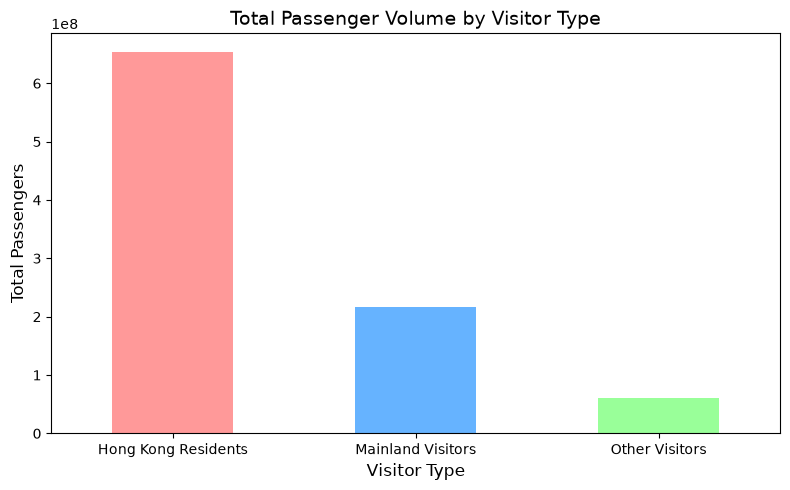

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 1. 屏蔽字体警告，强制重置为默认英文字体（彻底解决报错问题）
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib.font_manager')
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# 2. 读取数据并处理日期格式
df = pd.read_csv("新新出入境数据（英文版）.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

# ==========================================
# Plot 1: Line Chart - Monthly Total Trend
# ==========================================
# 按月聚合数据
monthly_trend = df.groupby(df['Date'].dt.to_period('M'))['Total'].sum().reset_index()
monthly_trend['Date'] = monthly_trend['Date'].dt.to_timestamp()

plt.figure(figsize=(10, 5))
plt.plot(monthly_trend['Date'], monthly_trend['Total'], marker='o', linestyle='-', color='b')
plt.title('Monthly Total Passenger Traffic Trend (2023-2026)', fontsize=14)
plt.xlabel('Date (Year-Month)', fontsize=12)
plt.ylabel('Total Passengers', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 2: Heatmap - Year/Month Traffic
# ==========================================
# 提取年份和月份
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
# 构建数据透视表
heatmap_data = df.groupby(['Year', 'Month'])['Total'].sum().unstack()

plt.figure(figsize=(10, 4))
sns.heatmap(heatmap_data, annot=False, cmap='YlOrRd', fmt='g', linewidths=.5)
plt.title('Heatmap of Total Passenger Traffic (Year-Month)', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Year', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 3: Bar Chart - Day of Week Effect
# ==========================================
# 提取星期并将标签改为英文简写
df['DayOfWeek'] = df['Date'].dt.dayofweek 
days_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}

# 计算每周各天的平均单日人流量
df_dow = df.groupby('DayOfWeek')['Total'].mean().reset_index()
df_dow['DayName'] = df_dow['DayOfWeek'].map(days_map)

plt.figure(figsize=(8, 5))
sns.barplot(x='DayName', y='Total', data=df_dow, hue='DayName', palette='viridis', legend=False)
plt.title('Day of Week Effect: Average Daily Passenger Traffic', fontsize=14)
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Average Passengers', fontsize=12)
plt.tight_layout()
plt.show()

# ==========================================
# Plot 4: Bar Chart - Passenger Composition
# ==========================================
visitor_types = ['Hong Kong Residents', 'Mainland Visitors', 'Other Visitors']
type_sums = df[visitor_types].sum()

plt.figure(figsize=(8, 5))
type_sums.plot(kind='bar', color=['#ff9999','#66b3ff','#99ff99'])
plt.title('Total Passenger Volume by Visitor Type', fontsize=14)
plt.xlabel('Visitor Type', fontsize=12)
plt.ylabel('Total Passengers', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [1]:
import numpy as np

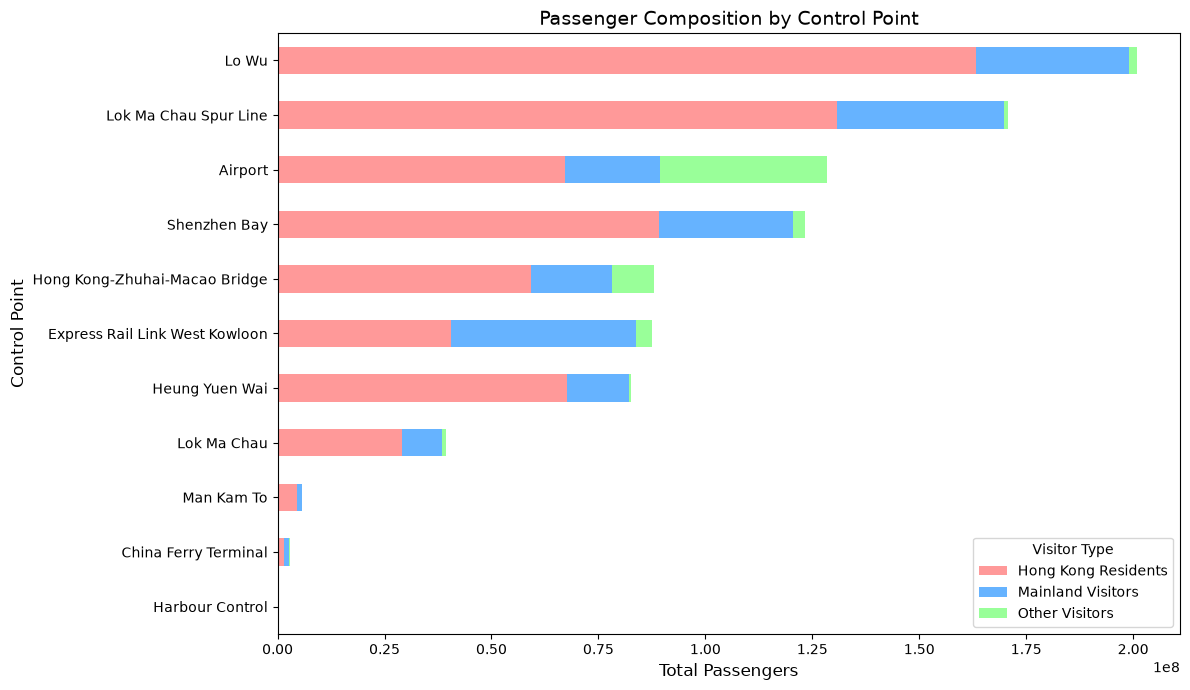

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings

# 1. 屏蔽掉底层所有关于字体的烦人警告（直接清净）
warnings.filterwarnings('ignore', category=UserWarning, module='matplotlib.font_manager')

# 2. 强制重置 Matplotlib 的全局设置到初始默认状态
plt.rcParams.update(plt.rcParamsDefault)

# 3. 显式指定绝对安全的英文字体
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# 读取数据
df = pd.read_csv("新新出入境数据（英文版）.csv")

# 提取三种旅客类型的列
visitor_types = ['Hong Kong Residents', 'Mainland Visitors', 'Other Visitors']

# 按口岸分组，并计算三种旅客的总量
cp_types = df.groupby('Control Point')[visitor_types].sum()

# 计算每个口岸的总客流量并排序
cp_types['Total_Sort'] = cp_types.sum(axis=1)
cp_types = cp_types.sort_values(by='Total_Sort', ascending=True).drop(columns='Total_Sort')

# 绘制横向堆叠柱状图
plt.figure(figsize=(12, 7))
cp_types.plot(
    kind='barh', 
    stacked=True, 
    color=['#ff9999', '#66b3ff', '#99ff99'], 
    ax=plt.gca()
)

# 纯英文标签
plt.title('Passenger Composition by Control Point', fontsize=14)
plt.xlabel('Total Passengers', fontsize=12)
plt.ylabel('Control Point', fontsize=12)
plt.legend(title='Visitor Type', loc='lower right')
plt.tight_layout()

# 显示图表
plt.show()